# 중심극한정리 시뮬레이션

---

## 1.

$X_1$, $X_2$, ... $X_n$ ~iid $Bernoulli(0.1) ⇒$ $\bar{X}$ $\approx$ $N(0.1, (\frac{0.3}{\sqrt{n}})^2)$

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats


def simulate_clt(n, m=2000):
    """
    중심극한정리(Central Limit Theorem, CLT)를 시뮬레이션하고 표본평균의 분포를 시각화하는 함수.

    매개변수:
    - n (int): 각 표본 집합의 크기(표본 수, Sample size).
               n이 커질수록 표본평균의 분포가 정규분포에 가까워짐.
    - m (int): 시뮬레이션 반복 횟수(표본평균의 개수, 기본값: 2000).
    """
    # 베르누이 시행의 성공 확률 (모평균 mu = p = 0.1, 모분산 sigma^2 = p * (1 - p) = 0.09)
    p = 0.1

    # 1. 시뮬레이션 수행:
    #    - stats.bernoulli(p).rvs(n): 성공 확률 0.1을 따르는 베르누이 확률표본 n개 추출
    #    - np.mean(...): 추출된 n개 표본의 평균(X_bar) 계산
    #    - 리스트 컴프리헨션을 통해 위 과정을 m번 반복하여 m개의 표본평균 수집
    sample_means = [np.mean(stats.bernoulli(p).rvs(n)) for _ in range(m)]

    # 2. 히스토그램 시각화:
    #    - bins=30: 구간 수를 30개로 설정
    #    - density=True: 빈도수가 아닌 확률밀도(면적의 합이 1)로 정규화하여 표시
    #    - alpha=0.6: 막대 투명도를 조절해 가독성 확보
    #    - label: 범례에 표본 크기(n) 명시
    plt.hist(sample_means, bins=30, density=True, alpha=0.6, label=f'n={n}')

    # 3. 그래프 서식 지정:
    plt.title(f"Sample Mean Distribution (n={n})")  # 그래프 제목 설정
    plt.xlabel("Sample Mean")                       # x축 레이블(표본평균)
    plt.ylabel("Density")                           # y축 레이블(확률밀도)

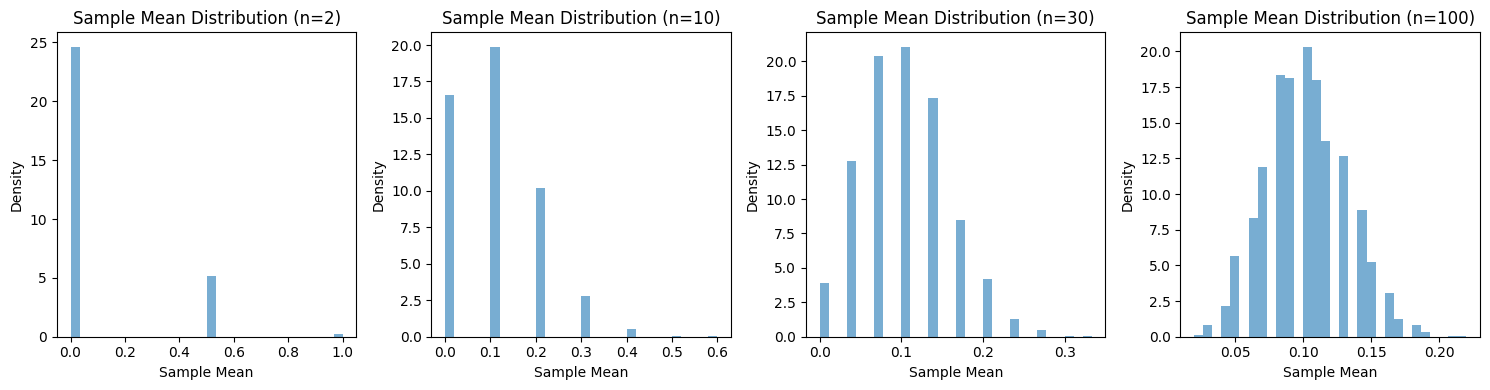

In [3]:
# n=2, 10, 30, 100일 때의 표본 크기 변화에 따른 중심극한정리 양상 비교

# 전체 캔버스 크기 설정 (가로 15인치, 세로 4인치)
plt.figure(figsize=(15, 4))

# 서로 다른 표본 크기(n) 리스트를 순회하며 인덱스(i)와 값(n)을 추출
for i, n in enumerate([2, 10, 30, 100]):
    # 1행 4열 그리드 중 (i + 1)번째 서브플롯 영역 활성화
    plt.subplot(1, 4, i + 1)

    # 해당 표본 크기 n에 대해 중심극한정리 시뮬레이션 및 히스토그램 그리기 함수 호출
    simulate_clt(n)

# 서브플롯 간의 제목, 축 레이블 등이 겹치지 않도록 여백을 자동 조정
plt.tight_layout()

# 화면에 시각화 결과 최종 출력
plt.show()

## 2.
$X_1$, $X_2$, ... $X_n$ ~iid $t_1 ⇒$ $\bar{X}$ $\approx t_1$ ($t_1$ : 코시 분포, 기댓값과 분산 정의 X)

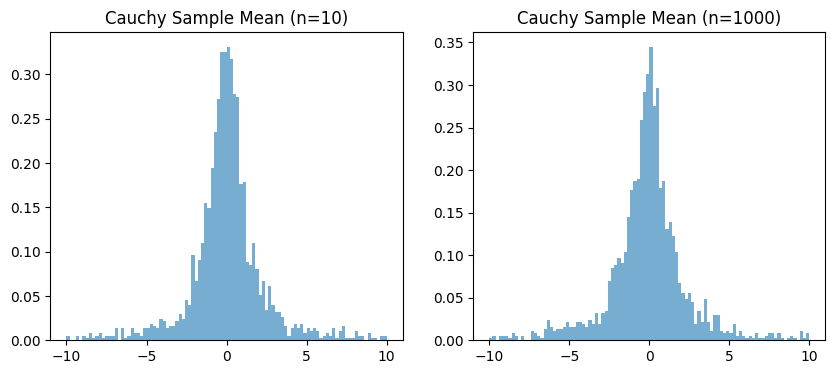

In [4]:
def simulate_cauchy(n, m=2000):
    # 자유도가 1인 코시분포에서 표본평균 시뮬레이션
    sample_means = [np.mean(stats.cauchy.rvs(size=n)) for _ in range(m)]

    # 시각화 (이상치가 너무 커서 범위를 제한)
    plt.hist(sample_means, bins=100, range=(-10, 10), density=True, alpha=0.6)
    plt.title(f"Cauchy Sample Mean (n={n})")

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); simulate_cauchy(10)
plt.subplot(1, 2, 2); simulate_cauchy(1000)
plt.show()

# 신뢰구간의 구축과 신뢰수준의 검증

----

## 모평균의 구간추정 검증


In [6]:
# 95% 신뢰구간 구성 함수
def get_confidence_interval(data, alpha=0.05):
    """
    정규분포 근정(Z-분포)을 기반으로 모평균의 (1 - alpha) * 100% 신뢰구간을 계산하는 함수.

    매개변수:
    - data (array-like): 분석 대상 1차원 표본 데이터
    - alpha (float): 유의수준 (기본값: 0.05 -> 95% 신뢰수준에 해당)

    반환값:
    - tuple: (신뢰구간 하한값, 신뢰구간 상한값)
    """
    # 1. 표본 크기(Sample size, n) 계산
    n = len(data)

    # 2. 표본평균(Sample mean, X_bar) 계산 - 점추정량
    x_bar = np.mean(data)

    # 3. 표본표준편차(Sample standard deviation, s) 계산
    #    - ddof=1: 자유도(Degrees of Freedom)를 n-1로 설정하여 불편추정량(비편향) 분산 계산
    s = np.std(data, ddof=1)

    # 4. 표준정규분포에서 양측 검정 기준 임계값(Critical value, z) 계산
    #    - stats.norm.ppf: 백분위수 함수(퍼센트 포인트 함수, 분위수 역함수)
    #    - alpha=0.05일 때 stats.norm.ppf(0.975) = 약 1.96 반환
    z = stats.norm.ppf(1 - alpha / 2)

    # 5. 오차의 한계(Margin of Error, MOE) 계산
    #    - 식: z * (s / sqrt(n)), 여기서 s / sqrt(n)은 표본평균의 표준오차(SE)
    margin_of_error = z * (s / np.sqrt(n))

    # 6. (하한, 상한) 형태의 신뢰구간 튜플 반환: [X_bar - MOE, X_bar + MOE]
    return (x_bar - margin_of_error, x_bar + margin_of_error)

위와 동일한 역할을 하는 함수를 `scipy`가 제공함

```python
from scipy import stats
import numpy as np

# stats.norm.interval(confidence, loc, scale)
# loc에는 표본평균, scale에는 표준오차(stats.sem 또는 s / sqrt(n))를 대입
stats.norm.interval(
    confidence=0.95,
    loc=np.mean(data),
    scale=stats.sem(data)
)
```

## 3.

sample : $X_1$, $X_2$, ..., $X_{64}$ ~ iid $N(10, 2^2)$ 의 실현 벡터  
신뢰 구간을 100번 재현

In [13]:
# 실제 모평균(True population mean, mu) 설정
true_mu = 10

# 95% 신뢰구간이 실제 모평균을 포함한 횟수를 기록할 카운터 초기화
hits = 0

# 표본 추출 및 신뢰구간 생성 과정을 100회 독립적으로 반복
for _ in range(100):
    # 모평균 10, 모표준편차 2를 따르는 정규분포 모집단에서 크기 n=64인 표본 무작위 추출
    sample = stats.norm(loc=true_mu, scale=2).rvs(64)

    # 추출한 표본 데이터를 기반으로 95% 신뢰구간(하한값 low, 상한값 high) 계산
    low, high = get_confidence_interval(sample)

    # 계산된 신뢰구간 내에 실제 모평균(true_mu)이 포함되는지 여부 검정
    if low <= true_mu <= high:
        hits += 1  # 모평균을 정상 포함했을 경우 카운트 1 증가

# 100회 시뮬레이션 중 모평균을 올바르게 포함한 신뢰구간의 개수(포함률, 이론상 약 95회) 출력
print(f"100번의 신뢰구간 중 참값을 포함한 횟수 : {hits}")

100번의 신뢰구간 중 참값을 포함한 횟수 : 97


In [14]:
true_mu = 10
hits = 0
for _ in range(1000):
    sample = stats.norm(loc=true_mu, scale=2).rvs(64)
    low, high = get_confidence_interval(sample)
    if low <= true_mu <= high :
        hits += 1

print(f"1000번의 신뢰구간 중 참값을 포함한 횟수 : {hits}")

1000번의 신뢰구간 중 참값을 포함한 횟수 : 943


In [15]:
true_mu = 10
hits = 0
for _ in range(10000):
    sample = stats.norm(loc=true_mu, scale=2).rvs(64)
    low, high = get_confidence_interval(sample)
    if low <= true_mu <= high :
        hits += 1

print(f"10000번의 신뢰구간 중 참값을 포함한 횟수 : {hits}")

10000번의 신뢰구간 중 참값을 포함한 횟수 : 9451


## 모비율의 구간 추정 : $n = 100$, $p=0.05$

In [21]:
# 설정: 실제 모비율(True population proportion, 클릭률) 5% (희귀 사건 가정)
true_p = 0.05

# n: 1회 시행당 추출할 표본 크기(Sample size = 100)
# m: 몬테카를로 시뮬레이션 반복 횟수(총 구간 생성 횟수 = 10,000)
n, m = 100, 10000

# 모비율(true_p)을 정상적으로 포함한 구간의 개수를 누적할 카운터 초기화
hits_p = 0

# m번의 독립적인 표본 추출 및 신뢰구간 추정 반복
for _ in range(m):
    # 모비율 0.05를 따르는 베르누이 분포에서 크기 n=100인 표본 데이터 추출 (성공 1, 실패 0)
    sample = stats.bernoulli(true_p).rvs(n)

    # 표본비율(Sample proportion, p_hat) 계산 - 점추정치
    p_hat = np.mean(sample)

    # 표본비율의 표준오차(Standard Error, SE) 계산: sqrt(p_hat * (1 - p_hat) / n)
    # - stats.bernoulli(p_hat).std()는 표본의 표준편차인 sqrt(p_hat * (1 - p_hat))를 산출함
    se = stats.bernoulli(p_hat).std() / np.sqrt(n)

    # 유효한 표준오차가 존재하는 경우 정규근사 신뢰구간 계산
    if se > 0:
        # 95% 신뢰수준(confidence=0.95)을 기준으로 표본비율의 정규분포 신뢰구간 도출
        low, high = stats.norm.interval(0.95, loc=p_hat, scale=se)
    else:
        # 표본이 전부 0(또는 1)으로 뽑혀 분산 및 표준오차가 0이 된 극단적 상황 처리 (구간 너비 = 0)
        low, high = p_hat, p_hat

    # 산출된 신뢰구간이 실제 모비율(true_p)을 포함하는지 판별
    if low <= true_p <= high:
        hits_p += 1  # 참값을 포함하면 카운트 증가

# 10,000회 시뮬레이션을 통해 계산된 포함 확률(커버리지, Coverage probability) 출력
# *참고: 설정한 신뢰수준이 0.95(95%)이므로, 정상 근사 시 약 0.95 안팎으로 수렴함
print(f"구간이 모수를 포함할 경험적 확률 : {hits_p / m:.4f}")

구간이 모수를 포함할 경험적 확률 : 0.8798


## 모비율의 구간 추정 : $n = 1000$, $p=0.05$

In [22]:
# 설정 : 실제 클릭률 5% (희귀 사건 가정)
true_p = 0.05
n, m = 1000, 10000
hits_p = 0

for _ in range(m):
    sample = stats.bernoulli(true_p).rvs(n)
    p_hat = np.mean(sample)
    se = stats.bernoulli(p_hat).std() / np.sqrt(n)
    if se > 0 :
        low, high = stats.norm.interval(0.95, loc=p_hat, scale=se)
    else:
        low, high = p_hat, p_hat # p_hat이 0 이거나 1인 극단적인 경우
    if low <= true_p <=high :
        hits_p += 1

print(f"구간이 모수를 포함할 경험적 확률 : {hits_p / m:.4f}")

구간이 모수를 포함할 경험적 확률 : 0.9422


## 모비율의 구간 추정 : $n = 100$, $p=0.3$

In [23]:
# 설정 : 실제 클릭률 30%
true_p = 0.3
n, m = 100, 10000
hits_p = 0

for _ in range(m):
    sample = stats.bernoulli(true_p).rvs(n)
    p_hat = np.mean(sample)
    se = stats.bernoulli(p_hat).std() / np.sqrt(n)
    if se > 0 :
        low, high = stats.norm.interval(0.95, loc=p_hat, scale=se)
    else:
        low, high = p_hat, p_hat # p_hat이 0 이거나 1인 극단적인 경우
    if low <= true_p <=high :
        hits_p += 1

print(f"구간이 모수를 포함할 경험적 확률 : {hits_p / m:.4f}")

구간이 모수를 포함할 경험적 확률 : 0.9508
